# Curso: Redes Neurais Convolucionais

Prof. [Denilson Alves Pereira](https://sites.google.com/ufla.br/denilsonpereira) <br>
Departamento de Ciência da Computação (DCC) <br>
Instituto de Ciências Exatas e Tecnológicas (ICET) <br> 
Universidade Federal de Lavras (UFLA)

# Atividade Prática 02

**Instruções:**
1. Siga os passos indicados em cada célula abaixo para completar a atividade.
2. Você deve inserir código somente entre as linhas marcadas com **INICIE O CÓDIGO AQUI** e **TERMINE O CÓDIGO AQUI**. Há uma indicação de quantas linhas de código são necessárias.
3. Em alguns pontos, confira o resultado esperado conforme marcado com **SAÍDA ESPERADA**.

**Tempo estimado para execução**: 1,5 hora

Versão: Agosto, 2021

## O Problema a ser Resolvido

O objetivo da atividade é elaborar uma solução de rede neural convolucional para a tarefa de reconhecimento facial. <br>

Será usado o [Dataset 5 Celebrity Faces](https://www.kaggle.com/dansbecker/5-celebrity-faces-dataset). Ele é um pequeno dataset que contém fotos das seguintes celebridades: Ben Affleck, Elton John, Jerry Seinfeld, Madonna, e Mindy Kaling.

Você vai praticar as seguintes habilidades:
- detectar e extrair as faces das pessoas que aparecem em uma imagem
- usar um modelo pré-treinado do sistema FaceNet para reconhecimento facial
- executar as tarefas de verificação facial e reconhecimento facial usando a abordagem de *threshold*
- executar a tarefa de reconhecimento facial usando a abordagem de um classificador de embeddings de imagens
- executar a tarefa de reconhecimento facial usando a abordagem de um classificador de imagens

## Pacotes

In [ ]:
import numpy as np # scientific computing
import tensorflow as tf  #  numerical computation using data flow graphs
from tensorflow import keras  # deep learning
import matplotlib.pyplot as plt # scientific plotting library
from sklearn.preprocessing import Normalizer # Normalizer class
from sklearn.preprocessing import LabelEncoder # LabelEnconder class
import os  # for accessing directory structure
from PIL import Image # Python Imaging Library
import mtcnn # face detection library

## Inicializações

In [ ]:
IMAGE_HEIGHT = 160 # altura da imagem (facenet)
IMAGE_WIDTH = 160  # largura da imagem (facenet)
IMAGE_SIZE = (IMAGE_HEIGHT, IMAGE_WIDTH) # tamanho da imagem
IMAGE_CHANNELS = 3  # número de canais RGB da imagem
DIR_DATA = './datasets/image-recognition/celebrity-faces'  # diretório contendo as imagens e o modelo
DIR_TRAIN = DIR_DATA+'/five-celebrity-dataset/train'
DIR_TEST  = DIR_DATA+'/five-celebrity-dataset/val'

## Detecção de Faces

Detecção de Face (*Face Detection*) é o processo de localizar automaticamente as faces em uma fotografia. A localização é marcada por uma caixa retangular enquadrando a face detectada.
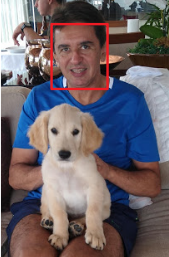

O MTCNN (*Multi-Task Cascaded Convolutional Neural Network*) é um modelo de aprendizagem para detecção de face descrito no artigo intitulado ["Joint Face Detection and Alignment Using Multitask Cascaded Convolutional Networks"](https://arxiv.org/abs/1604.02878).

Uma implementação desse modelo pode ser instalada pelo comando: <br>
pip install mtcnn

Trecho de código adaptado de https://machinelearningmastery.com/how-to-develop-a-face-recognition-system-using-facenet-in-keras-and-an-svm-classifier/

In [ ]:
def extract_first_face(filename):
    """
    Extract the first face from the image in a file
    
    Arguments:
        filename -- name of the file containing a image
        
    Returns:
        face -- image of the first face
    """
    # load image from file
    image = Image.open(filename)
    # convert to RGB, if needed
    image = image.convert('RGB')
    # convert to array
    pixels = np.asarray(image)
    # create the detector, using default weights
    detector = mtcnn.MTCNN()
    # detect faces in the image
    results = detector.detect_faces(pixels)
    # extract the bounding box from the first face
    x1, y1, width, height = results[0]['box']
    x1, y1 = abs(x1), abs(y1) # bug fix
    x2, y2 = x1 + width, y1 + height
    # extract the face
    face = pixels[y1:y2, x1:x2]
    face = Image.fromarray(face.astype(np.uint8), 'RGB')

    return face

In [ ]:
def get_faces(dirname, image_size=(IMAGE_HEIGHT, IMAGE_WIDTH)):
    """
    Get faces from images in a directory
    
    Arguments:
        dirname -- name of the directory containing images
        image_size -- size of the face images to be returned
        
    Returns:
        dataX -- numpy array containing the face images
        dataY -- array containing the categories
    """
    # get file names and categories
    dirnames = os.listdir(dirname)
    filenames = []
    categories = []
    for dname in dirnames:
        filesdir = os.listdir(dirname+'/'+dname)
        for filen in filesdir:
            filenames.append(filen)
            categories.append(dname) # category = directory name
    # extract faces and resize images
    num_images = len(filenames)
    dataX = np.zeros((num_images, image_size[0], image_size[1], IMAGE_CHANNELS))
    dataY = []
    for i in range(num_images):
        img = extract_first_face(dirname+'/'+categories[i]+'/'+filenames[i])
        img = img.resize(image_size)
        dataX[i] = np.asarray(img)/255.
        dataY.append(categories[i])

    return dataX, dataY

In [ ]:
# Get images from training directory
dataX, dataY = get_faces(DIR_TRAIN)

In [ ]:
# Visualization of random images
delta = 5
n = np.random.randint(low=0,high=dataX.shape[0]-2*delta,dtype=int)
# plot the faces 
plt.subplot(2,2,1)
plt.imshow(dataX[n])
plt.title(dataY[n])
plt.subplot(2,2,2)
plt.imshow(dataX[n+delta])
plt.title(dataY[n+delta])
plt.subplot(2,2,3)
plt.imshow(dataX[n-delta])
plt.title(dataY[n-delta])
plt.subplot(2,2,4)
plt.imshow(dataX[n+delta*2])
plt.title(dataY[n+delta*2])
plt.show()

## Geração de *Embeddings* usando o FaceNet

- A verificação e reconhecimento facial serão feitos a partir de um modelo pré-treinado do sistema [FaceNet](https://arxiv.org/pdf/1503.03832.pdf). Treinar um bom modelo de reconhecimento facial exige um número muito grande de imagens e um alto poder computacional.
- O modelo FaceNet foi treinado usando a função *Triplet Loss*. Essa função tem como objetivo aproximar as codificações de duas imagens da mesma pessoa (âncora e positivo), enquanto distancia as codificações de duas imagens de pessoas diferentes (âncora e negativo).
- O modelo FaceNet gera *embeddings* para cada imagem facial. Os *embeddings* são vetores com 128 elementos. A rede usa imagens RGB de dimensão 160x160 como entrada e produz como saída vetores de 128 elementos, os quais codificam cada imagem de face de entrada.
- O vetor de codificação de tamanho 128 é obtido por meio de uma camada completamente conectada com 128 neurônios como a última camada da rede.
- A vantagem de se gerar *embeddings* é uma computação mais rápida. Os *embeddings* podem ser usados como entrada para um classificador tradicional para o reconhecimento facial, em vez de se usar as imagens originais.

### FaceNet *Triplet Loss*

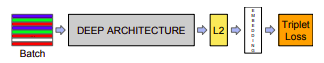
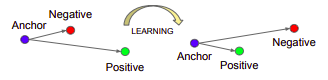

O treinamento da rede neural usa trios de imagens $(A, P, N)$:
- A é uma imagem "Âncora" - a imagem de uma pessoa
- P é uma imagem "Positiva" - a imagem da mesma pessoa que a imagem âncora
- N é uma imagem "Negativa" - a imagem de uma pessoa diferente daquela da imagem âncora

Considere que $(A^{(i)}, P^{(i)}, N^{(i)})$ denota o $i$-ésimo exemplo de treino. A imagem âncora $A^{(i)}$ de uma pessoa deve estar mais próxima da imagem Positiva $P^{(i)}$ do que da imagem Negativa $N^{(i)}$) por, pelo menos, uma margem $\alpha$:

$$\mid \mid f(A^{(i)}) - f(P^{(i)}) \mid \mid_2^2 + \alpha < \mid \mid f(A^{(i)}) - f(N^{(i)}) \mid \mid_2^2$$

O objetivo é minimizar a função de custo "triplet cost":

$$\mathcal{J} = \sum^{m}_{i=1} max(\small \underbrace{\mid \mid f(A^{(i)}) - f(P^{(i)}) \mid \mid_2^2}_\text{(1)} - \underbrace{\mid \mid f(A^{(i)}) - f(N^{(i)}) \mid \mid_2^2}_\text{(2)} + \alpha, 0) \tag{3}$$

- Para uma imagem $x$, a codificação $f(x)$ é a função computada pela rede neural.
- O termo (1) é a distância ao quadrado entre a âncora "A" e a imagem positiva "P" para um dado trio. O objetivo é que essa distância seja pequena.
- O termo (2) é a distância ao quadrado entre a âncora "A" e a imagem negativa "N" para um dado trio. O objetivo é que essa distância seja relativamente grande. O termo tem um sinal negativo o precedendo, assim, minimizar o negativo do termo é o mesmo que maximizar o termo.
- $\alpha$ é chamado de margem. Ela é um hiperparâmetro que deve ser especificado manualmente. Um valor usual é $\alpha = 0.2$. 
- A maioria das implementações redimensiona os vetores codificados para terem a norma L2 igual a 1 (i.e., $\mid \mid f(img)\mid \mid_2$=1).

Usaremos os seguinte modelo FaceNet pré-treinado:

MS-Celeb-1M dataset - Keras FaceNet Pre-Trained Model (88 megabytes) 
https://drive.google.com/drive/folders/1pwQ3H4aJ8a6yyJHZkTwtjcL4wYWQb7bn

In [ ]:
# load the pretrained facenet model
model = tf.keras.models.load_model(DIR_DATA+'/ms-celeb-model/model/facenet_keras.h5', compile=False)
print(model.inputs)
print(model.outputs)

#### Padronização dos Embeddings

O modelo FaceNet que está sendo usado espera que os valores dos pixels das imagens sejam padronizados pela média e desvio padrão, conforme código abaixo.

In [ ]:
# padronização para geração dos embeddings
dataX = dataX.astype('float32')
for i in range(len(dataX)):
    mean, std = dataX[i].mean(), dataX[i].std()
    dataX[i] = (dataX[i] - mean) / std

In [ ]:
# use the pretrained model to generate the embeddings 
dataY_embeddings = model.predict(dataX)

In [ ]:
dataY_embeddings.shape

#### Normalização dos Embeddings

É uma boa prática normalizar os vetores de embeddings, pois os vetores são comparados uns com os outros usando-se uma métrica de distância. A distância Euclidiana é uma das métricas mais usadas quando as variáveis são de tipos similares, como é o caso das imagens faciais. A distância Euclidiana é a distância mais curta entre dois pontos em um espaço N-dimensional (Espaço Euclidiano). Ela é também conhecida como Norma Euclidiana, Métrica Euclidiana, Norma L2, Métrica L2 e Métrica Pitagoreana.

Por definição, a norma L2 é a distância euclidiana entre o ponto do vetor e a sua origem. Ela é calculada como a raiz quadrada da soma dos quadrados dos valores do vetor. Já a distância (métrica) entre dois vetores (dois pontos) pode ser definida como a norma da diferença desses dois vetores. Assim, distância é sempre entre dois pontos e norma é sempre para um vetor. Mais detalhes neste link: https://paulrohan.medium.com/euclidean-distance-and-normalization-of-a-vector-76f7a97abd9

Normalização de dados é usada em aprendizagem de máquina para tornar o modelo de treinamento menos sensível à escala das medidas. Isso permite ao modelo convergir para melhores pesos e, consequentemente, conduz a um modelo mais preciso. Normalizar um vetor em matemática é dividir cada um dos seus elementos por algum valor V, de forma que o comprimento/norma do vetor resultante seja igual a 1. Isso faz com que V seja igual ao comprimento do vetor.

A Normalização L2 é definida como a técnica de normalização que modifica os valores do dataset de forma que em cada linha a raiz quadrada da soma dos quadrados de seus valores seja igual a 1. É também chamada de quadrados mínimos.

In [ ]:
# normalize input vectors (L2 norm)
in_encoder = Normalizer(norm='l2')
dataY_embeddings = in_encoder.transform(dataY_embeddings)

## Verificação Facial (*Face Verification*)

A tarefa de verificação facial certifica se a pessoa na imagem da câmera é a mesma de uma imagem pré-cadastrada (imagem de referência).

Neste exemplo, vamos criar um banco de dados (*database*) usando um dicionário. A chave do dicionário será a identificação (nome) da pessoa e o valor será uma lista com os embeddings das imagens faciais daquela pessoa.

A imagem de referência de cada pessoa será aquela na primeira posição do dicionário. As outras imagens serão usadas para a verificação.

Um sistema de verificação facial para ser útil deve apresentar uma acurária de, pelo menos, 99,9%

In [ ]:
# Observe que as identificações das pessoas estão ordenadas
dataY

In [ ]:
# Cria o banco de dados
database = {}
i = 0
while (i < len(dataY)):
    cat = dataY[i] # identificação
    database[cat] = []
    while (i < len(dataY) and cat == dataY[i]):
        database[cat].append(dataY_embeddings[i])
        i += 1

#### Função para verificação facial

Duas imagens são consideradas similares se a distância entre elas for menor que um limiar (*threshold*).

In [ ]:
def verify(embed_image, identity, database):
    """
    Function that verifies if the person on the "embed_image_norm" image is "identity".
    
    Arguments:
    embed_image -- embedding of a image normalized by L2 norm
    identity -- string, id of the person you'd like to verify the identity
    database -- python dictionary mapping id of allowed people to their encodings (vectors).
                Consider the first image in the list the ID image to be compared
    
    Returns:
    dist -- distance between the "embed_image" and the image of "identity" in the database.
    verifyOk -- True, if the they are the same person. False otherwise.
    """

    # Compute distance with identity's image
    dist = np.linalg.norm(embed_image - database[identity][0])  # zero is the index of the reference image
    
    # Verification is ok if dist < 1.1, else verification is not confirmed
    verifyOk = dist < 1.1
        
    return dist, verifyOk

In [ ]:
# verifica as imagens no database de cada celebridade contra a imagem dela na posição zero
# contabiliza a taxa de acertos
true_pos = 0
total = 0
for (id, db_img_list) in database.items(): # para cada celebridade
    for img in range(1, len(db_img_list)): # para cada imagem da celebridade corrente, exceto a referência 0
        dist, verifyOk = verify(db_img_list[img], id, database)
        if verifyOk:
            true_pos += 1
        total += 1
print('Taxa de acertos = %.2f' %(true_pos/total*100), '%')

Observe que a taxa de acertos foi baixa, o que significa que algumas imagens não estão sendo reconhecidas com sendo da própria pessoa. As causas possíveis são as diferentes tonalidades de luz, as posições das faces, resoluções diferentes, imagens coloridas e em escala de cinza etc.

Exemplo: verifique se a imagem no índice 1 do Elton John é similar àquela de referência do database (índice 0). <br>
Experimente alterar esse índice para verificar outras imagens do Elton John.

In [ ]:
dist, verifyOk = verify(database['elton_john'][1], 'elton_john', database)
dist, verifyOk

Experimente agora com a Madonna. <br>
Observe que com a Madonna a taxa de acertos é muito baixa.

In [ ]:
dist, verifyOk = verify(database['madonna'][1], 'madonna', database)
dist, verifyOk

Execute a célula abaixo para ver a imagem de referência da Madonna

In [ ]:
plt.imshow(dataX[0])
plt.title(dataY[0])

E a imagem do índice 1 da Madonna:

In [ ]:
plt.imshow(dataX[1])
plt.title(dataY[1])

In [ ]:
# verifica as imagens de referência no database de cada celebridade contra as imagens de outras celebridades
# contabiliza a taxa de acertos
false_pos = 0
total = 0
celeb = ['madonna', 'ben_afflek', 'mindy_kaling', 'jerry_seinfeld', 'elton_john']
for cel1 in range(0, len(celeb)): # para cada celebridade
    for cel2 in range(cel1+1, len(celeb)):
        for img in range(len(database[celeb[cel2]])):
            dist, verifyOk = verify(database[celeb[cel2]][img], celeb[cel1], database)
            if verifyOk:
                false_pos += 1
            total += 1
print('Taxa de acertos = %.2f' %((total-false_pos)/total*100), '%')

A taxa de acertos foi de 100%, o que significa que uma pessoa não vai ser confundida com outra pessoa diferente.

Experimente alterar a distância mínima (*threshold*) da função 'verify' para ver se as taxas de acertos melhoram. Você vai perceber que ao melhorar a verificação facial vai piorar o reconhecimento facial. Execute novamente os códigos acima para testar.

## Reconhecimento Facial (*Face Recognition*)

A tarefa de reconhecimento facial verifica quem é a pessoa da imagem da câmera consultando um banco de dados de imagens pré-cadastradas.

Neste exemplo, vamos usar o mesmo banco de dados (*database*) criado anteriormente, por meio de um dicionário. A chave do dicionário será a identificação (nome) da pessoa e o valor será uma lista com os embeddings das imagens faciais daquela pessoa.

A imagem na posição zero da lista de imagens de cada pessoa será usada para verificação, ela não será usada pela função abaixo.

In [ ]:
def recognize(embed_image, database):
    """
    Implements face recognition by finding who is the person on the image embedding.
    
    Arguments:
    embed_image -- embedding of a image normalized by L2 norm
    database -- python dictionary mapping id of allowed people to their encodings (vectors).
                The first image in the list of each ID will not be considered
    
    Returns:
    min_dist -- the minimum distance between the embed_image and each image in the database
    identity -- the id prediction for the person on embed_image
    """
    
    # Initialize "min_dist" to a large value, say 100
    min_dist = 100
    # Loop over the database dictionary's ids and encodings
    for (id, db_img_list) in database.items():
        for j in range(1, len(db_img_list)):
            # Compute distance with identity's image
            dist = np.linalg.norm(embed_image - database[id][j])
            # If this distance is less than the min_dist, then set min_dist to dist, and id to identity
            if dist < min_dist:
                min_dist = dist
                identity = id

    if min_dist > 1.1: # threshold
        identity = 'unknown'  # Not in the database
        
    return min_dist, identity

In [ ]:
# reconhece a Madonna
min_dist, identity = recognize(database['madonna'][0], database)
min_dist, identity

In [ ]:
# reconhece o Ben Afflek
min_dist, identity = recognize(database['ben_afflek'][0], database)
min_dist, identity

In [ ]:
# reconhece a Mindy Kaling
min_dist, identity = recognize(database['mindy_kaling'][0], database)
min_dist, identity

In [ ]:
# reconhece o Jerry Seinfeld
min_dist, identity = recognize(database['jerry_seinfeld'][0], database)
min_dist, identity

In [ ]:
# reconhece o Elton John
min_dist, identity = recognize(database['elton_john'][0], database)
min_dist, identity

Observe que todas as pessoas foram corretamente reconhecidas.

#### Face desconhecida

Experimente carregar uma foto do seu rosto (ou outro rosto qualquer) e fazer o reconhecimento.
- use a função 'extract_first_face' se a imagem não contiver apenas o seu rosto
- a imagem da face deve ser 160x160x3. Use a função 'resize' se necessário
- padronize os pixels da imagem pela média e desvio padrão
- gere o embedding pelo modelo FaceNet
- normalize o embedding pela norma L2
- faça o reconhecimento usando a função 'recognize'

In [ ]:
### INICIE O CÓDIGO AQUI ### (várias linhas de código / várias células)


### TERMINE O CÓDIGO AQUI ###

**SAÍDA ESPERADA**: <br>
____, unknown

---

## Reconhecimento Facial usando um Classificador

A vantagem do reconhecimento facial baseado em um limiar (*theshold*), como apresentado acima, é que quando uma nova pessoa for adicionada ao banco de dados, não é necessário treinar todo o modelo novamente para que ela seja reconhecida. Nesse caso, basta gerar e adicionar o *embedding* da nova imagem no banco de dados. Quando se usa uma abordagem de classificação, todo o modelo deve ser treinado novamente, o que pode não ser uma boa solução.

Na abordagem de classificação, pode-se usar um método tradicional de aprendizagem de máquina, como o SVM, ou mesmo uma rede neural densa, tendo como entrada os *embeddings* das imagens. A vantagem é a eficiência, pois é mais rápido gerar os embeddings das imagens por meio de um modelo pré-treinado do que treinar um modelo com as imagens originais.

A seguir, vamos avaliar as duas opções de classificação: (i) usando os embeddings das imagens e (ii) usando as imagens originais.

### Reconhecimento Facial usando um Classificador Tradicional por meio dos Embeddings das Imagens

Nesta etapa, vamos implementar um classificador para reconhecimento facial usando um método tradicional de aprendizagem de máquina denominado [Support Vector Machines (SVM)](https://machinelearningmastery.com/support-vector-machines-for-machine-learning/).

As entradas para o classificador serão os *embeddings* das imagens. O SVM é muito eficaz para classificar dados desse tipo, separando *embeddings* das faces. Vamos usar a classe [SVC do sciki-learn](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

#### Pré-processamento dos dados de treino e teste

In [ ]:
# training data has already been used before, let's just rename the variables to make it easier to understand
trainY = dataY
trainY_embeddings = dataY_embeddings

In [ ]:
# get the faces for the test data
testX,  testY  = get_faces(DIR_TEST)

In [ ]:
testY

In [ ]:
# convert the string target variables for each celebrity name to integers
# label encode targets
out_encoder = LabelEncoder()
out_encoder.fit(trainY)
trainY = out_encoder.transform(trainY)
testY  = out_encoder.transform(testY)

In [ ]:
testY

In [ ]:
# standardization for the generation of embeddings
testX = testX.astype('float32')
for i in range(len(testX)):
    mean, std = testX[i].mean(), testX[i].std()
    testX[i] = (testX[i] - mean) / std

In [ ]:
# use the pretrained model to generate the embeddings 
testY_embeddings = model.predict(testX)

In [ ]:
# normalize input vectors (L2 norm)
in_encoder = Normalizer(norm='l2')
testY_embeddings = in_encoder.transform(testY_embeddings)

#### Classificação

In [ ]:
# import libraries
from sklearn.svm import SVC # SVM class
from sklearn.metrics import accuracy_score # accuracy metric

In [ ]:
# train
svc_model = SVC(kernel='linear', probability=True)
svc_model.fit(trainY_embeddings, trainY)

In [ ]:
# predict
train_pred = svc_model.predict(trainY_embeddings)
test_pred = svc_model.predict(testY_embeddings)

In [ ]:
# score
train_acc = accuracy_score(trainY, train_pred)
test_acc = accuracy_score(testY, test_pred)
print('Accuracy: train = %.2f, test = %.2f' % (train_acc*100, test_acc*100))

**SAÍDA ESPERADA**: <br>

Accuracy: train = 100.00, test = 100.00


### Tarefa extra (não será avaliada)

Experimente usar a probabilidade de predição do classificador para verificar a confiança com que ele classificou algumas das instâncias.

Experimente também carregar uma foto do seu rosto (ou de um outro rosto qualquer que não esteja no conjunto de treino), verificar a predição do classificador e a probabilidade com que ele faz a predição. Atribua um limiar (*threshold*) para que o classificador possa classificar uma face como não reconhecida.

Dica: use o *embedding* da face desconhecida já obtida em atividade anterior deste notebook (acima). 

In [ ]:
### INICIE O CÓDIGO AQUI ### (várias linhas de código / várias células)


### TERMINE O CÓDIGO AQUI ###

### Reconhecimento Facial usando um Classificador de Imagens

Vamos implementar agora o reconhecimento facial usando um classifidor de imagens, sem usar os embeddings, por meio de uma rede neural convolucional. A rede receberá como entrada as imagens das faces, após o passo de detecção de faces.

#### Pré-processamento dos dados de treino e teste

In [ ]:
# Get images from data directory
trainX, trainY = get_faces(DIR_TRAIN)
testX,  testY  = get_faces(DIR_TEST)

In [ ]:
# convert the string target variables for each celebrity name to integers
# label encode targets
out_encoder = LabelEncoder()
out_encoder.fit(trainY)
trainY = out_encoder.transform(trainY)
testY  = out_encoder.transform(testY)

In [ ]:
# encodes labels in one hot encoding format
trainY = tf.keras.utils.to_categorical(trainY, num_classes = 5)
testY  = tf.keras.utils.to_categorical(testY, num_classes = 5)

#### Definição do Modelo

Defina o modelo da rede usando camadas de convolução + pooling + densa.

A imagem de entrada tem tamanho 160x160x3 e são 5 classes.

Documentação: <br>
Keras: https://keras.io/ <br>
Classe *Model*: https://keras.io/api/models/model/ <br>
Classe *Sequential*:https://keras.io/api/models/sequential/#sequential-class <br>
Camadas: https://www.tensorflow.org/api_docs/python/tf/keras/layers <br>
Funções de ativação disponíveis: https://keras.io/api/layers/activations/ 

In [ ]:
### INICIE O CÓDIGO AQUI ### (~9 linhas de código)


### TERMINE O CÓDIGO AQUI ###

In [ ]:
# Prints a summary of the network, showing its architecture and parameters.
model.summary()

#### Compilação do Modelo

Compile o model usando os seguintes parâmetros:
- Função de perda: categorical_crossentropy
- Otimizador: adam
- Métricas: accuracy

Dica 1: use a função *compile*: https://keras.io/api/models/model_training_apis/ <br>
Dica 2: relação de funções de perda: https://www.tensorflow.org/api_docs/python/tf/keras/losses <br>
Dica 3: relação de otimizadores: https://www.tensorflow.org/api_docs/python/tf/keras/optimizers <br>
Dica 4: relação de métricas: https://keras.io/api/metrics/

In [ ]:
### INICIE O CÓDIGO AQUI ### (1 linha de código)

### TERMINE O CÓDIGO AQUI ###

#### Treinamento do Modelo

Ajusta o modelo aos dados de treinamento.
Devem ser fornecidos os dados de treinamento e o número de épocas (iterações). Uma época é composta por uma única passagem por todos os exemplos do conjunto de treino.

Efetue o treinamento do modelo usando os dados de treino *trainX* e *trainY*.

Documentação: https://keras.io/api/models/model_training_apis/

In [ ]:
### INICIE O CÓDIGO AQUI ### (1 linha de código)

### TERMINE O CÓDIGO AQUI ###

**SAÍDA ESPERADA**: <br>

Você deve conseguir uma acurácia de 100% no treino. Experimente com, pelo menos, 20 épocas.

---

#### Avaliação do Modelo

Avalie o desempenho da rede no conjunto de teste usando os dados de teste *testX* e *testY*.

Documentação: https://keras.io/api/models/model_training_apis/

In [ ]:
### INICIE O CÓDIGO AQUI ### (1 linha de código)

### TERMINE O CÓDIGO AQUI ###
print("Loss: %.4f" % loss, "\nAccuracy: %.4f" % acc)

**SAÍDA ESPERADA**: <br>

Você deve conseguir uma acurácia de, pelo menos, 84%.

---

## Predição

Prediz a saída de novos dados.

Documentação: <br>
Função *predict*: https://keras.io/api/models/model_training_apis/ <br>
Função *argmax*: https://numpy.org/doc/stable/reference/generated/numpy.argmax.html

Na classificação multiclasse, *model.predict* retorna um vetor de probabilidades para cada classe. A função *argmax* retorna o índice do vetor com a maior probabilidade, indicando assim a classe predita.

In [ ]:
predictions = model.predict(testX)
print("Predictions: ", [np.argmax(x, axis=-1) for x in predictions[:30]]) # print the first 30 predictions
print("\nCorrect:     ", [np.argmax(x, axis=-1) for x in testY[:30]])

### Tarefa extra (não será avaliada)

Experimente usar as imagens originais, sem o passo de detecção de faces, como entrada para a rede neural convolucional. Relate o seu resultado.

In [ ]:
### INICIE O CÓDIGO AQUI ### (várias linhas de código / várias células)

### TERMINE O CÓDIGO AQUI ###

# Fim

Parabéns! Você efetuou todos os passos para a implementação da tarefa de reconhecimento facial.

Os experimentos mostram que usar os embeddings das imagens a partir de um modelo de reconhecimento facial pré-treinado indicam melhores resultados do que treinar um modelo com as imagens originais.

-------------------------------------------